Leave-one-source-out (LOSO) SVM

In [ ]:
import json
import pickle
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC

SPLITS_ROOT = Path("../../data/splits")
ARTIFACTS_DIR = Path("../../data/artifacts")
WEIGHTS_ROOT = Path("../../weights")
RESULTS_DIR = Path("../../../results/svm/loso")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(ARTIFACTS_DIR / "label_encoder.pkl", "rb") as f:
    label_encoder = pickle.load(f)
LABEL_ORDER = list(label_encoder.classes_)

SOURCES = ["df1", "df5"]
print("Folds:", SOURCES)

MAX_FEATURES = 50000
NGRAM_RANGE = (1, 2)
MIN_DF = 2
SUBLINEAR_TF = True
C = 1.0

Folds: ['df1', 'df5']


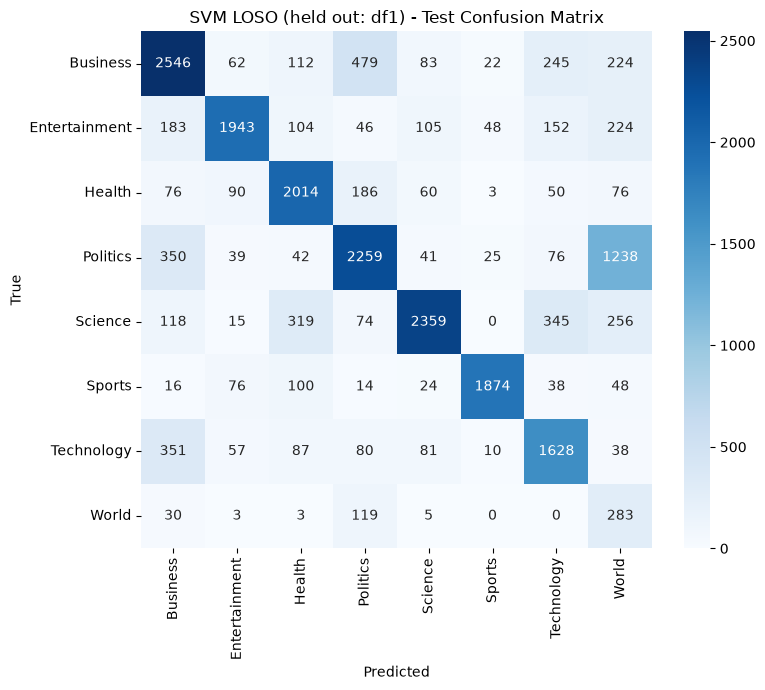

loso_df1: macro_f1=0.6678 (n_test=21654, classes=8, train_time=33.5s)


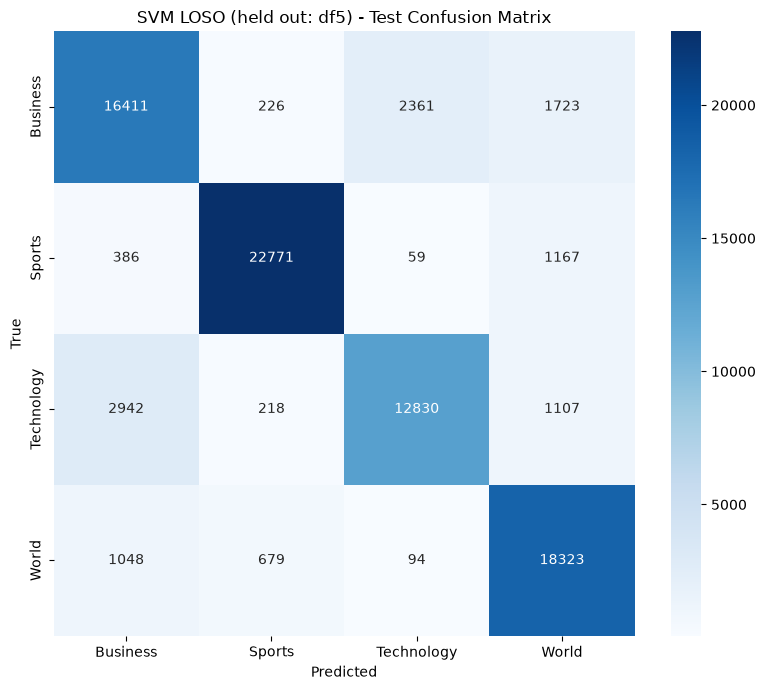

loso_df5: macro_f1=0.6897 (n_test=119911, classes=4, train_time=31.7s)


,held_out_source,n_train,n_test,n_classes_present,macro_f1,train_time_sec
0,df1,254600,21654,8,0.667774,33.510423
1,df5,171082,119911,4,0.689698,31.718311


In [2]:
loso_results = []

for held_out in SOURCES:
    fold_dir = SPLITS_ROOT / f"loso_{held_out}"
    train_df = pd.read_csv(fold_dir / "train.csv")
    test_df = pd.read_csv(fold_dir / "test.csv")

    y_train = label_encoder.transform(train_df["category"])
    y_test = label_encoder.transform(test_df["category"])
    present_classes = np.unique(y_test)
    present_class_names = label_encoder.inverse_transform(present_classes).tolist()

    vectorizer = TfidfVectorizer(
        max_features=MAX_FEATURES, ngram_range=NGRAM_RANGE, min_df=MIN_DF, sublinear_tf=SUBLINEAR_TF
    )
    X_train = vectorizer.fit_transform(train_df["text"])
    X_test = vectorizer.transform(test_df["text"])

    model = LinearSVC(C=C)
    start_time = time.time()
    model.fit(X_train, y_train)
    train_time_sec = time.time() - start_time

    inf_start = time.time()
    y_pred = model.predict(X_test)
    inf_time_sec = time.time() - inf_start

    macro_f1 = f1_score(y_test, y_pred, labels=present_classes, average="macro", zero_division=0)
    report_dict = classification_report(
        y_test,
        y_pred,
        labels=present_classes,
        target_names=present_class_names,
        output_dict=True,
        zero_division=0,
    )

    cm = confusion_matrix(y_test, y_pred, labels=present_classes)
    plt.figure(figsize=(8, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=present_class_names, yticklabels=present_class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(f"SVM LOSO (held out: {held_out}) - Test Confusion Matrix")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{held_out}_confusion_matrix.png", dpi=150)
    plt.show()
    plt.close()

    fold_weights_dir = WEIGHTS_ROOT / f"loso_{held_out}" / "svm"
    fold_weights_dir.mkdir(parents=True, exist_ok=True)
    with open(fold_weights_dir / "svm_model.pkl", "wb") as f:
        pickle.dump(model, f)
    with open(fold_weights_dir / "vectorizer.pkl", "wb") as f:
        pickle.dump(vectorizer, f)

    metrics = {
        "model_family": "svm",
        "model_name": "linear-svm-tfidf-loso",
        "run_timestamp": datetime.now(timezone.utc).isoformat(),
        "label_order": LABEL_ORDER,
        "loso_held_out_source": held_out,
        "loso_classes_present": present_class_names,
        "config": {
            "max_features": MAX_FEATURES,
            "ngram_range": list(NGRAM_RANGE),
            "min_df": MIN_DF,
            "sublinear_tf": SUBLINEAR_TF,
            "C": C,
        },
        "train": {
            "n_train": len(train_df),
            "n_val": None,
            "train_time_sec": train_time_sec,
        },
        "test": {
            "n_test": len(test_df),
            "n_classes_present": len(present_classes),
            "macro_f1": macro_f1,
            "inf_time_sec": inf_time_sec,
            "per_class": {
                name: report_dict[name] for name in present_class_names
            },
            "confusion_matrix": cm.tolist(),
        },
    }

    with open(fold_weights_dir / "config.json", "w", encoding="utf-8") as f:
        json.dump(metrics["config"], f, indent=2)

    with open(RESULTS_DIR / f"{held_out}_metrics.json", "w", encoding="utf-8") as f:
        json.dump(metrics, f, indent=2)

    loso_results.append(
        {
            "held_out_source": held_out,
            "n_train": len(train_df),
            "n_test": len(test_df),
            "n_classes_present": len(present_classes),
            "macro_f1": macro_f1,
            "train_time_sec": train_time_sec,
        }
    )
    print(f"loso_{held_out}: macro_f1={macro_f1:.4f} (n_test={len(test_df)}, classes={len(present_classes)}, train_time={train_time_sec:.1f}s)")

loso_results_df = pd.DataFrame(loso_results)
loso_results_df

In [3]:
loso_results_df.to_csv(RESULTS_DIR / "svm_loso_summary.csv", index=False, encoding="utf-8")
print("Wrote:", (RESULTS_DIR / "svm_loso_summary.csv").resolve())
print("\nIn-distribution SVM_a macro_f1 for comparison: 0.8146 (see results/svm/SVM_a_metrics.json)")
print("Mean LOSO macro_f1:", loso_results_df["macro_f1"].mean())

Wrote: D:\UoL\Sem2\mnu2\results\svm\loso\svm_loso_summary.csv

In-distribution SVM_a macro_f1 for comparison: 0.8146 (see results/svm/SVM_a_metrics.json)
Mean LOSO macro_f1: 0.678735967136952
